<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/10_Expectation_Maximization_(EM)_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Expectation-Maximization (EM) Algorithm Implementation

This notebook demonstrates a step-by-step implementation of the Expectation-Maximization algorithm using a 1D Gaussian Mixture Model (GMM).

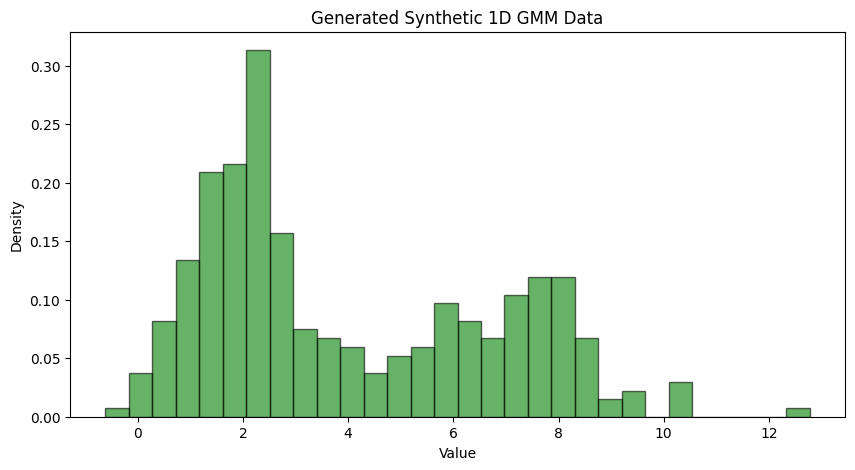

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Generate synthetic data from two Gaussians
np.random.seed(42)

# True parameters
mu1_true, sigma1_true = 2.0, 1.0
mu2_true, sigma2_true = 7.0, 1.5
pi_true = 0.6  # fraction of data from component 1

N = 300
n_samples_1 = int(N * pi_true)
n_samples_2 = N - n_samples_1

# Generate samples
x1 = np.random.normal(mu1_true, sigma1_true, n_samples_1)
x2 = np.random.normal(mu2_true, sigma2_true, n_samples_2)
X = np.concatenate([x1, x2])

# Shuffle data
np.random.shuffle(X)

# Plot the generated data histogram
plt.figure(figsize=(10, 5))
plt.hist(X, bins=30, density=True, alpha=0.6, color='g', edgecolor='black')
plt.title('Generated Synthetic 1D GMM Data')
plt.xlabel('Value')
plt.ylabel('Density')
plt.show()

Now, let's implement the EM algorithm itself to recover these parameters.

In [3]:
def em_algorithm(X, n_iterations=20):
    # Initialize parameters randomly
    mu1, mu2 = np.random.choice(X), np.random.choice(X)
    sigma1, sigma2 = np.std(X), np.std(X)
    pi = 0.5

    print(f"Initial Guesses: mu1={mu1:.2f}, mu2={mu2:.2f}, sigma1={sigma1:.2f}, sigma2={sigma2:.2f}, pi={pi:.2f}\n")

    for i in range(n_iterations):
        # --- E-Step: Compute responsibilities (gammas) ---
        # Likelihood of each data point belonging to component 1 & 2
        gamma1 = pi * norm.pdf(X, mu1, sigma1)
        gamma2 = (1 - pi) * norm.pdf(X, mu2, sigma2)

        # Normalize so they sum to 1 for each data point
        total_gamma = gamma1 + gamma2
        gamma1 /= total_gamma
        gamma2 /= total_gamma

        # Effective number of points assigned to each component
        N1 = np.sum(gamma1)
        N2 = np.sum(gamma2)

        # --- M-Step: Update parameters ---
        mu1 = np.sum(gamma1 * X) / N1
        mu2 = np.sum(gamma2 * X) / N2

        sigma1 = np.sqrt(np.sum(gamma1 * (X - mu1)**2) / N1)
        sigma2 = np.sqrt(np.sum(gamma2 * (X - mu2)**2) / N2)

        pi = N1 / len(X)

        if i % 5 == 0 or i == n_iterations - 1:
            print(f"Iteration {i+1}:")
            print(f"  Component 1: mu={mu1:.2f}, sigma={sigma1:.2f}, pi={pi:.2f}")
            print(f"  Component 2: mu={mu2:.2f}, sigma={sigma2:.2f}, pi={1-pi:.2f}")

    return (mu1, sigma1), (mu2, sigma2), pi

(mu1_est, sigma1_est), (mu2_est, sigma2_est), pi_est = em_algorithm(X, n_iterations=30)

Initial Guesses: mu1=3.89, mu2=0.08, sigma1=2.76, sigma2=2.76, pi=0.50

Iteration 1:
  Component 1: mu=4.90, sigma=2.77, pi=0.66
  Component 2: mu=2.23, sigma=1.66, pi=0.34
Iteration 6:
  Component 1: mu=6.03, sigma=2.35, pi=0.52
  Component 2: mu=1.80, sigma=0.79, pi=0.48
Iteration 11:
  Component 1: mu=6.58, sigma=1.92, pi=0.46
  Component 2: mu=1.84, sigma=0.84, pi=0.54
Iteration 16:
  Component 1: mu=6.83, sigma=1.70, pi=0.43
  Component 2: mu=1.90, sigma=0.88, pi=0.57
Iteration 21:
  Component 1: mu=6.89, sigma=1.65, pi=0.42
  Component 2: mu=1.92, sigma=0.89, pi=0.58
Iteration 26:
  Component 1: mu=6.90, sigma=1.64, pi=0.42
  Component 2: mu=1.92, sigma=0.90, pi=0.58
Iteration 30:
  Component 1: mu=6.91, sigma=1.63, pi=0.42
  Component 2: mu=1.92, sigma=0.90, pi=0.58


Let's plot the fitted distributions over our dataset to visualize how well the EM algorithm recovered the true components.

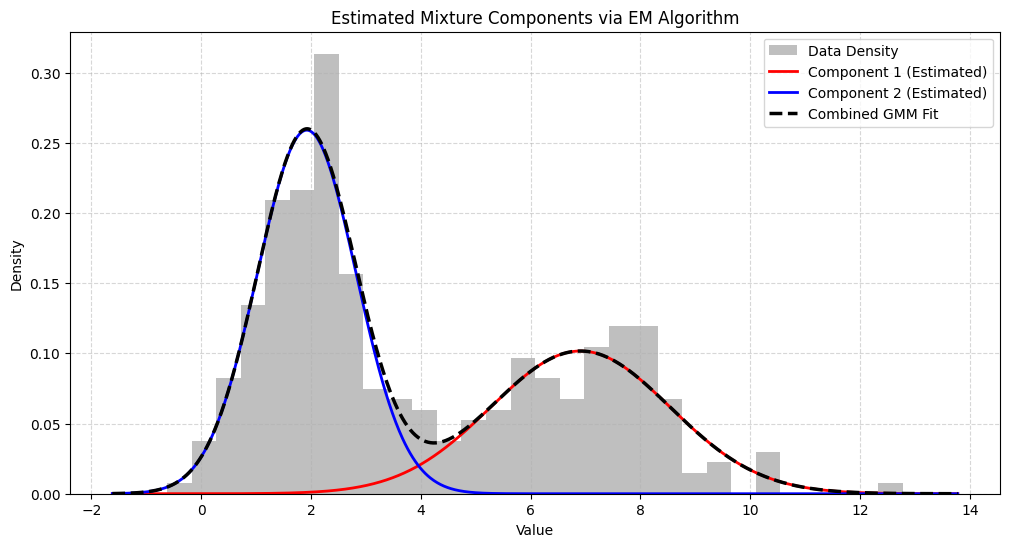

In [4]:
plt.figure(figsize=(12, 6))
plt.hist(X, bins=30, density=True, alpha=0.5, color='gray', label='Data Density')

x_axis = np.linspace(min(X) - 1, max(X) + 1, 1000)

# Estimated PDFs scaled by estimated mixing weights
pdf1 = pi_est * norm.pdf(x_axis, mu1_est, sigma1_est)
pdf2 = (1 - pi_est) * norm.pdf(x_axis, mu2_est, sigma2_est)

plt.plot(x_axis, pdf1, 'r-', linewidth=2, label=f'Component 1 (Estimated)')
plt.plot(x_axis, pdf2, 'b-', linewidth=2, label=f'Component 2 (Estimated)')
plt.plot(x_axis, pdf1 + pdf2, 'k--', linewidth=2.5, label='Combined GMM Fit')

plt.title('Estimated Mixture Components via EM Algorithm')
plt.xlabel('Value')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()